# MCP

In [1]:
# Imports and environment first, all in one place

from dotenv import load_dotenv
from IPython.display import Image, display
from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.agents.middleware import wrap_tool_call
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langchain_mcp_adapters.client import MultiServerMCPClient

load_dotenv(override=True)

True

In [2]:
!node --version
!npx --version

v25.2.1
11.6.2


⠙⠹⠸⠼Navigating to https://F1.com
Capturing screenshot into f1.png
⠙

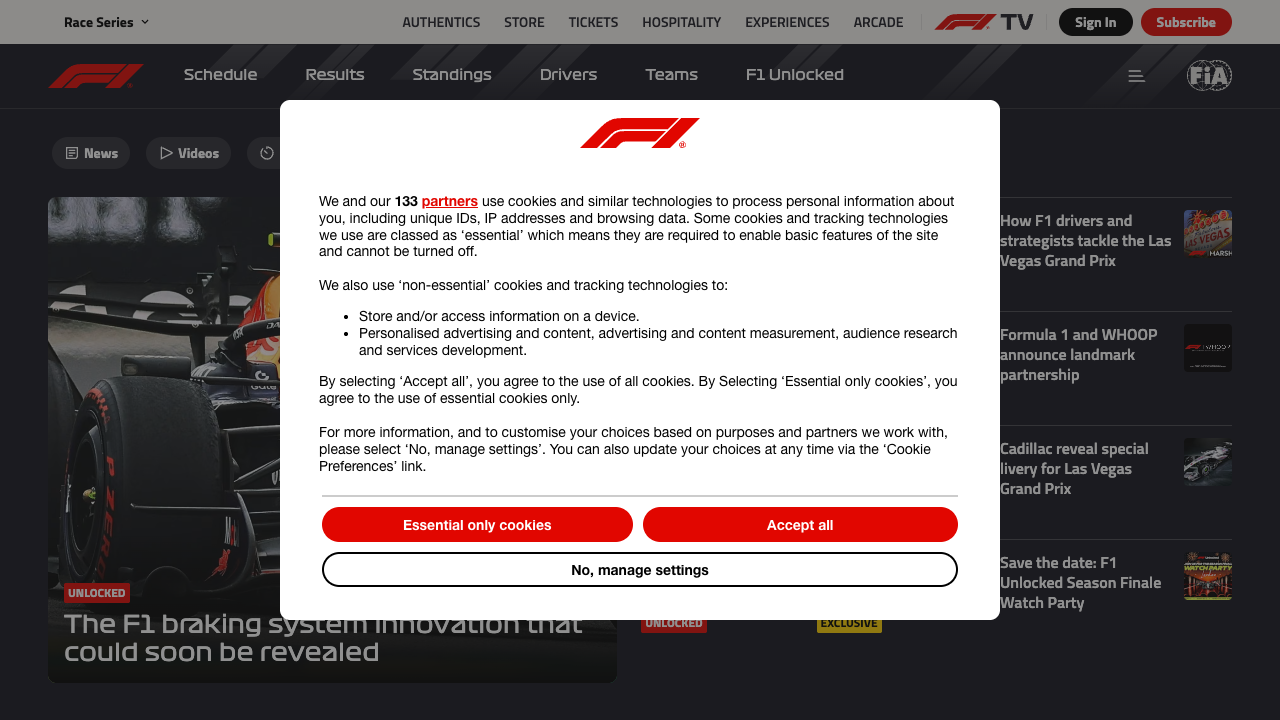

In [4]:
!npx -y playwright@latest screenshot --channel=chrome https://F1.com f1.png
display(Image("f1.png"))

In [5]:
client = MultiServerMCPClient({
    "playwright": {
        "transport": "stdio",
        "command": "npx",
        "args": ["-y", "@playwright/mcp@latest", "--isolated"],
    }
})

browser_tools = await client.get_tools()
print(f"Loaded {len(browser_tools)} browser tools:")
for t in browser_tools:
    print(" -", t.name)

Loaded 25 browser tools:
 - browser_close
 - browser_resize
 - browser_console_messages
 - browser_handle_dialog
 - browser_emulate_media
 - browser_evaluate
 - browser_file_upload
 - browser_drop
 - browser_find
 - browser_fill_form
 - browser_press_key
 - browser_type
 - browser_navigate
 - browser_navigate_back
 - browser_network_requests
 - browser_network_request
 - browser_run_code_unsafe
 - browser_take_screenshot
 - browser_snapshot
 - browser_click
 - browser_drag
 - browser_hover
 - browser_select_option
 - browser_tabs
 - browser_wait_for


In [8]:
browser_agent = create_agent(
    model="openai:gpt-5.5",
    tools=browser_tools,
    system_prompt="""
    You are an F1 research assistant.
    Use the browser tools to complete the task.

    When browsing:
    - Inspect the page for cookie banners or pop-ups.
    - If a cookie banner appears, click "Accept all" or the
      equivalent consent button.
    - 
    - Use the actual buttons and selectors found on the page.
    - After clicking, inspect the page again to confirm it worked.
    - Navigate to the relevant standings page if necessary.
    - Report the championship year, rankings and points clearly.
    - If you cannot access the information, explain the issue
      rather than guessing.
    """,
)

result = await browser_agent.ainvoke({
    "messages": [{
        "role": "user",
        "content": (
            "Go to https://www.bbc.co.uk/sport/formula1 "
            "and tell me the current drivers' world championship rankings."
        ),
    }]
})

print(result["messages"][-1].content)

BBC Sport’s current **FIA Formula 1 Drivers’ World Championship standings** are for the **2026 championship** — last updated by BBC on **8 November 2026 at 22:15**.

| Rank | Driver | Team | Points |
|---:|---|---|---:|
| 1 | Kimi Antonelli | Mercedes | 390 |
| 2 | Max Verstappen | Red Bull | 279 |
| 3 | George Russell | Mercedes | 262 |
| 4 | Lewis Hamilton | Ferrari | 261 |
| 5 | Charles Leclerc | Ferrari | 249 |
| 6 | Lando Norris | McLaren | 246 |
| 7 | Oscar Piastri | McLaren | 152 |
| 8 | Isack Hadjar | Red Bull | 122 |
| 9 | Liam Lawson | Racing Bulls | 89 |
| 10 | Pierre Gasly | Alpine | 42 |
| 11 | Arvid Lindblad | Racing Bulls | 38 |
| 12 | Franco Colapinto | Alpine | 27 |
| 13 | Oliver Bearman | Haas | 23 |
| 14 | Gabriel Bortoleto | Audi | 14 |
| 15 | Nico Hulkenberg | Audi | 14 |
| 16 | Esteban Ocon | Haas | 7 |
| 17 | Fernando Alonso | Aston Martin | 7 |
| 18 | Carlos Sainz Jnr | Williams | 7 |
| 19 | Alexander Albon | Williams | 5 |
| 20 | Yuki Tsunoda | Racing Bulls | 1